In [ ]:
import requests
import zipfile
import io
import os
import pandas as pd


In [ ]:
# Define the URL for the student.zip file which contains student-mat.csv
student_mat_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00320/student.zip"

In [ ]:
try:
    response = requests.get(student_mat_url, timeout=15)
    response.raise_for_status()  # Raise HTTPError for bad responses (4xx, 5xx)
    print("Dataset downloaded successfully.")
except requests.exceptions.Timeout:
    raise RuntimeError("Request timed out while trying to reach the UCI repository.")
except requests.exceptions.ConnectionError:
    raise RuntimeError("Network error: Unable to connect to the UCI repository.")
except requests.exceptions.HTTPError as e:
    raise RuntimeError(f"HTTP error occurred: {e}")
except requests.exceptions.RequestException as e:
    raise RuntimeError(f"Unexpected error during dataset download: {e}")

Dataset downloaded successfully.


In [ ]:
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    print("Files available in ZIP archive:")
    for file in z.namelist():
        print(" -", file)

Files available in ZIP archive:
 - student-mat.csv
 - student-por.csv
 - student-merge.R
 - student.txt


In [ ]:
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    with z.open('student-mat.csv') as f:
        df = pd.read_csv(f, sep=';')


In [ ]:
#Basic dataset inspection
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
df.head()

Dataset shape: (395, 33)

First 5 rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [ ]:
# Pass = 1 if final grade G3 >= 10, else Fail = 0

df['pass'] = (df['G3'] >= 10).astype(int)

# Drop G3 to avoid data leakage
X = df.drop(columns=['G3', 'pass'])
y = df['pass']

print("target distrubution: " , y.value_counts())


target distrubution:  pass
1    265
0    130
Name: count, dtype: int64


In [ ]:
#Identify categorical and numerical features
categorical_cols = X.select_dtypes(include=['object']).columns
numerical_cols = X.select_dtypes(exclude=['object']).columns

print("Categorical columns:", list(categorical_cols))
print("Numerical columns:", list(numerical_cols))

Categorical columns: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
Numerical columns: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']


In [ ]:
#Encode categorical variables using One-Hot Encoding
# drop_first=True avoids dummy variable trap
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

print("Encoded feature shape:", X_encoded.shape)


Encoded feature shape: (395, 41)


In [ ]:
# Train-test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y  # preserve class distribution
)

In [ ]:
# Feature scaling (important for Logistic Regression)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit scaler only on training data to avoid data leakage
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [ ]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(
    penalty='l2',
    C=1.0,
    solver='liblinear',
    class_weight='balanced',  # handle class imbalance
    max_iter=1000
)

log_reg.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, solver='liblinear')

In [ ]:
# Cell 15: Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)
# Predictions
y_pred = log_reg.predict(X_test_scaled)
y_prob = log_reg.predict_proba(X_test_scaled)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1-score :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))

print('classification report')
print(classification_report(y_test, y_pred))

Accuracy : 0.8607594936708861
Precision: 0.9565217391304348
Recall   : 0.8301886792452831
F1-score : 0.8888888888888888
ROC-AUC  : 0.9404934687953557
classification report
              precision    recall  f1-score   support

           0       0.73      0.92      0.81        26
           1       0.96      0.83      0.89        53

    accuracy                           0.86        79
   macro avg       0.84      0.88      0.85        79
weighted avg       0.88      0.86      0.86        79



In [ ]:
# Interpret model coefficients (feature importance)
import numpy as np

coefficients = pd.DataFrame({
    'Feature': X_encoded.columns,
    'Coefficient': log_reg.coef_[0],
    'Odds_Ratio': np.exp(log_reg.coef_[0])
}).sort_values(by='Odds_Ratio', ascending=False)

coefficients.head(10)


# Most influential negative features (risk factors)


,Feature,Coefficient,Odds_Ratio
14,G2,3.842588,46.646061
13,G1,1.830969,6.239927
10,Walc,0.764933,2.148851
25,Fjob_other,0.658582,1.932051
15,school_MS,0.610384,1.841138
6,famrel,0.482928,1.620814
38,higher_yes,0.216662,1.241925
3,traveltime,0.199976,1.221373
27,Fjob_teacher,0.199545,1.220848
22,Mjob_services,0.168737,1.183809


In [ ]:
#most important features for a student to pass
coefficients.head(10)


,Feature,Coefficient,Odds_Ratio
14,G2,3.842588,46.646061
13,G1,1.830969,6.239927
10,Walc,0.764933,2.148851
25,Fjob_other,0.658582,1.932051
15,school_MS,0.610384,1.841138
6,famrel,0.482928,1.620814
38,higher_yes,0.216662,1.241925
3,traveltime,0.199976,1.221373
27,Fjob_teacher,0.199545,1.220848
22,Mjob_services,0.168737,1.183809


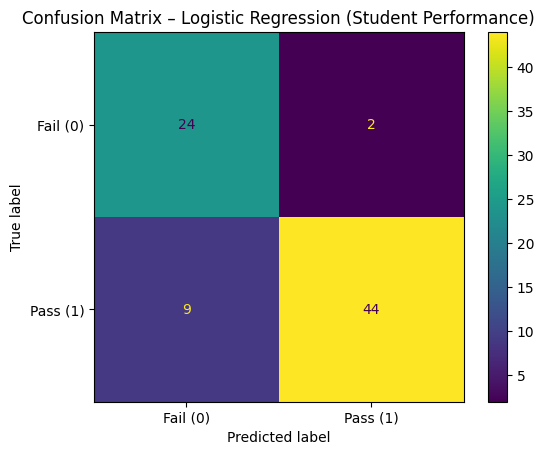

confusion matrix: [[24  2]
 [ 9 44]]


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Fail (0)', 'Pass (1)']
)

disp.plot()
plt.title('Confusion Matrix – Logistic Regression (Student Performance)')
plt.show()


# Cell 19: Confusion Matrix Values Explained
# True Negatives  (TN): Correctly predicted Fail students
# False Positives (FP): Predicted Pass but actually Fail
# False Negatives (FN): Predicted Fail but actually Pass
# True Positives  (TP): Correctly predicted Pass students

print('confusion matrix:', cm)